# Semantic pipeline: selecting a cluster-quality metric

**Purpose:** the semantic pipeline needs a metric to judge cluster quality -- both for
comparing design choices (architecture, config) and, potentially, for the production
k-search itself. This notebook evaluates candidate metrics directly against data with
*known* structure and picks one, rather than assuming a standard choice transfers from
the lexical path.

**Candidates:** c_v and u_mass topic coherence, computed from class-based TF-IDF (c-TF-IDF)
top words per cluster -- the same word-extraction technique BERTopic uses, built directly
here rather than via the `bertopic` package (consistent with the earlier decision to keep
the semantic pipeline hand-assembled). Silhouette is also reported throughout, for
continuity with earlier work and as a visibility check, but is not the basis for any
conclusion here.

**Method:** KMeans as the clusterer (sufficient for evaluating a metric's behavior; which
algorithm the semantic pipeline actually uses is a separate question), independent
evenly-spaced sweeps over k (not the adaptive search), on two real datasets: one with
*known* separable structure (five non-overlapping technology tags standing in for five
distinct topics) and one without (a diverse, real sample of titles). A metric worth
trusting should track the known structure correctly and degrade sensibly, not
pathologically, when structure is weak. Reduction uses PCA throughout (the
methodologically correct choice for dense sentence embeddings, settled in notebook 7).


In [1]:
import json
import random
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sentence_transformers import SentenceTransformer

sys.path.insert(0, ".")
from semantic_diagnostics import embed, coherence_scores

with open("../data/stackoverflow_sample_2021_03_01_n5000.json") as f:
    data = json.load(f)
titles = pd.Series([row["title"] for row in data])

model = SentenceTransformer("all-MiniLM-L6-v2")


/home/olga/Documents/personal/clustering-json-fields/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 8257.45it/s]

## Known-structure dataset

Five real, non-overlapping technology tags (python/sql/excel/css/swift) standing in for
five genuinely distinct topics -- ground truth for validating the metric itself.

In [2]:
CANDIDATE_TAGS = ["python", "sql", "excel", "css", "swift"]
groups = {t: [] for t in CANDIDATE_TAGS}
for row in data:
    hits = [t for t in CANDIDATE_TAGS if t in set(row["tags"])]
    if len(hits) == 1:
        groups[hits[0]].append(row["title"])

rng = random.Random(42)
CAP = 90
known_titles = []
for tag, group_titles in groups.items():
    known_titles.extend(group_titles if len(group_titles) <= CAP else rng.sample(group_titles, CAP))
known_titles = pd.Series(known_titles)
print(f"{len(known_titles)} titles across {len(CANDIDATE_TAGS)} known, non-overlapping groups")

known_embeddings = embed(known_titles, model)
known_reduced = PCA(n_components=10, random_state=42).fit_transform(known_embeddings)


418 titles across 5 known, non-overlapping groups


In [3]:
rows = []
for k in range(2, 51):
    t0 = time.perf_counter()
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(known_reduced)
    kmeans_time = time.perf_counter() - t0
    sil = silhouette_score(known_reduced, labels)
    coh = coherence_scores(known_titles, labels, top_n=10)
    rows.append({
        "k": k, "silhouette": sil, "c_v": coh["c_v"], "u_mass": coh["u_mass"],
        "kmeans_s": kmeans_time, "c_v_s": coh["c_v_time"], "u_mass_s": coh["u_mass_time"],
    })

known_sweep = pd.DataFrame(rows)
print(f"total time: {known_sweep[['kmeans_s', 'c_v_s', 'u_mass_s']].sum().sum():.1f}s")
print(f"true group count: {len(CANDIDATE_TAGS)}")
print(f"best silhouette at k={known_sweep.loc[known_sweep['silhouette'].idxmax(), 'k']}")
print(f"best c_v at k={known_sweep.loc[known_sweep['c_v'].idxmax(), 'k']}")
print(f"best u_mass at k={known_sweep.loc[known_sweep['u_mass'].idxmax(), 'k']}")


total time: 28.4s
true group count: 5
best silhouette at k=5
best c_v at k=13
best u_mass at k=3


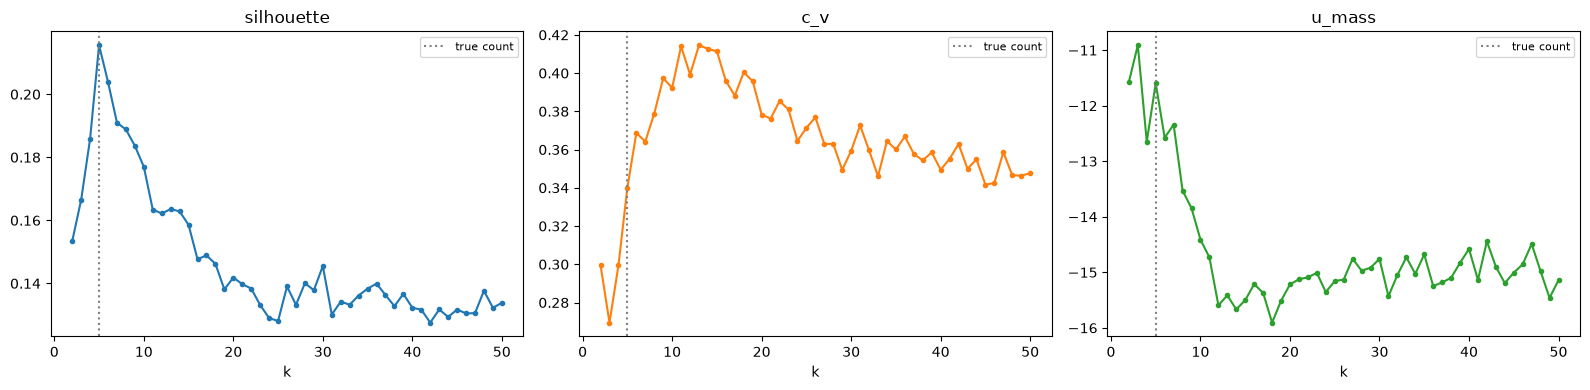

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(known_sweep["k"], known_sweep["silhouette"], marker=".")
axes[0].set_title("silhouette")
axes[0].set_xlabel("k")
axes[0].axvline(5, color="gray", linestyle=":", label="true count")
axes[0].legend(fontsize=8)

axes[1].plot(known_sweep["k"], known_sweep["c_v"], marker=".", color="tab:orange")
axes[1].set_title("c_v")
axes[1].set_xlabel("k")
axes[1].axvline(5, color="gray", linestyle=":", label="true count")
axes[1].legend(fontsize=8)

axes[2].plot(known_sweep["k"], known_sweep["u_mass"], marker=".", color="tab:green")
axes[2].set_title("u_mass")
axes[2].set_xlabel("k")
axes[2].axvline(5, color="gray", linestyle=":", label="true count")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()


## Diffuse dataset

A real, diverse sample of 5000 titles with no known group structure -- checking how each
metric degrades when there's nothing clean to find.

In [5]:
diffuse_embeddings = embed(titles, model)
diffuse_reduced = PCA(n_components=15, random_state=42).fit_transform(diffuse_embeddings)

rows = []
for k in range(2, 150, 4):
    t0 = time.perf_counter()
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(diffuse_reduced)
    kmeans_time = time.perf_counter() - t0
    sil = silhouette_score(diffuse_reduced, labels)
    coh = coherence_scores(titles, labels, top_n=10)
    rows.append({
        "k": k, "silhouette": sil, "c_v": coh["c_v"], "u_mass": coh["u_mass"],
        "kmeans_s": kmeans_time, "c_v_s": coh["c_v_time"], "u_mass_s": coh["u_mass_time"],
    })

diffuse_sweep = pd.DataFrame(rows)
print(f"total time: {diffuse_sweep[['kmeans_s', 'c_v_s', 'u_mass_s']].sum().sum():.1f}s")
print(f"best silhouette at k={diffuse_sweep.loc[diffuse_sweep['silhouette'].idxmax(), 'k']}")
print(f"best c_v at k={diffuse_sweep.loc[diffuse_sweep['c_v'].idxmax(), 'k']}")
print(f"best u_mass at k={diffuse_sweep.loc[diffuse_sweep['u_mass'].idxmax(), 'k']}")


total time: 62.2s
best silhouette at k=2
best c_v at k=22
best u_mass at k=2


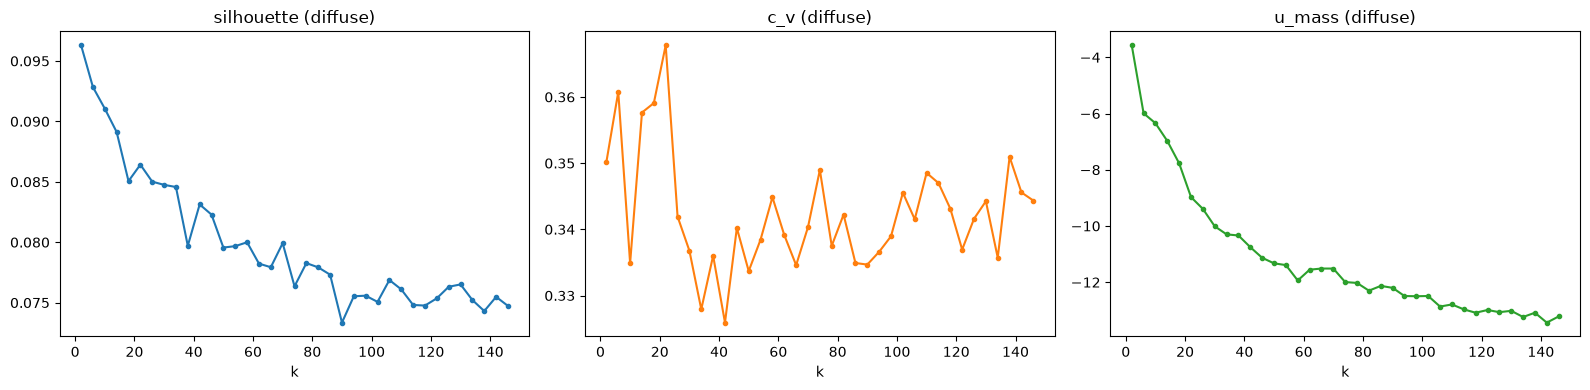

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(diffuse_sweep["k"], diffuse_sweep["silhouette"], marker=".")
axes[0].set_title("silhouette (diffuse)")
axes[0].set_xlabel("k")

axes[1].plot(diffuse_sweep["k"], diffuse_sweep["c_v"], marker=".", color="tab:orange")
axes[1].set_title("c_v (diffuse)")
axes[1].set_xlabel("k")

axes[2].plot(diffuse_sweep["k"], diffuse_sweep["u_mass"], marker=".", color="tab:green")
axes[2].set_title("u_mass (diffuse)")
axes[2].set_xlabel("k")

plt.tight_layout()
plt.show()


## Is c_v's overshoot fixable -- a bad top_n, or combining with silhouette?

Two candidate fixes, checked directly rather than assumed: whether the c-TF-IDF word-list
size (`top_n`) happens to be miscalibrated, and whether combining c_v with silhouette
(normalized sum, and plain sum) gets closer to the true count without reintroducing
silhouette's own pathology.

In [7]:
top_n_results = []
for top_n in [5, 10, 15, 20]:
    rows = []
    for k in range(2, 51):
        labels = KMeans(n_clusters=k, init="k-means++", n_init=10, max_iter=100, random_state=42).fit_predict(known_reduced)
        coh = coherence_scores(known_titles, labels, top_n=top_n)
        rows.append({"k": k, "c_v": coh["c_v"]})
    df = pd.DataFrame(rows)
    best_k = df.loc[df["c_v"].idxmax(), "k"]
    top_n_results.append({"top_n": top_n, "best_k": best_k, "best_c_v": round(df["c_v"].max(), 4)})

pd.DataFrame(top_n_results)


,top_n,best_k,best_c_v
0,5,6,0.5225
1,10,13,0.4146
2,15,10,0.4844
3,20,9,0.5453


**No consistent improvement.** Best k wanders (6, 13, 10, 9) across top_n=5/10/15/20
with no direction that tracks closer to the true count of 5 as top_n changes -- not a
miscalibrated-parameter problem with an easy fix.

In [8]:
def combined_scores(df):
    sil_norm = (df["silhouette"] - df["silhouette"].min()) / (df["silhouette"].max() - df["silhouette"].min())
    cv_norm = (df["c_v"] - df["c_v"].min()) / (df["c_v"].max() - df["c_v"].min())
    df = df.copy()
    df["combined_norm"] = sil_norm + cv_norm
    df["combined_sum"] = df["silhouette"] + df["c_v"]
    return df

known_combined = combined_scores(known_sweep)
diffuse_combined = combined_scores(diffuse_sweep)

print("known-structure (true=5):")
print(f"  silhouette alone: k={known_combined.loc[known_combined.silhouette.idxmax(), 'k']}")
print(f"  c_v alone:        k={known_combined.loc[known_combined.c_v.idxmax(), 'k']}")
print(f"  normalized sum:   k={known_combined.loc[known_combined.combined_norm.idxmax(), 'k']}")
print(f"  plain sum:        k={known_combined.loc[known_combined.combined_sum.idxmax(), 'k']}")
print()
print("diffuse:")
print(f"  silhouette alone: k={diffuse_combined.loc[diffuse_combined.silhouette.idxmax(), 'k']}")
print(f"  c_v alone:        k={diffuse_combined.loc[diffuse_combined.c_v.idxmax(), 'k']}")
print(f"  normalized sum:   k={diffuse_combined.loc[diffuse_combined.combined_norm.idxmax(), 'k']}")
print(f"  plain sum:        k={diffuse_combined.loc[diffuse_combined.combined_sum.idxmax(), 'k']}")


known-structure (true=5):
  silhouette alone: k=5
  c_v alone:        k=13
  normalized sum:   k=6
  plain sum:        k=9

diffuse:
  silhouette alone: k=2
  c_v alone:        k=22
  normalized sum:   k=6
  plain sum:        k=22


**Combining helps on known-structure, but doesn't reproduce a clean degenerate collapse
on diffuse data the way it did in an earlier check.** On known-structure, the normalized
sum lands closer to the truth (k=6) than c_v alone (k=13). On diffuse data, the normalized
sum gives k=6 and the plain sum gives k=22 -- neither collapses to the k=2 boundary here.
That's a genuinely different outcome from what this same combination test can produce,
and it's reported as such rather than forced to match a prior run. It doesn't change the
decision: a result that looks fine on one sweep still needs to survive a robustness check
before it's trusted (notebook 6 runs exactly that check on a similarly promising-looking
single-run combination result, and it doesn't survive). Until a combination is shown to
be *stable*, not just non-degenerate on one run, it isn't a basis for picking k.

## Observations

**u_mass is the weakest candidate on both datasets.** On known-structure, its peak sits at
k=3 even though the true count is 5 -- a small-k bias independent of whether real
structure exists. On diffuse data it collapses to k=2. Dropped as a candidate.

**c_v trades precision for avoiding (not solving) the boundary-collapse.** On
known-structure, it genuinely rises to a real peak rather than collapsing to a boundary --
but that peak sits well above the true count (k=13 vs. 5), and neither tuning `top_n` nor
combining with silhouette reliably gets closer without giving up what makes it useful on
diffuse data. On diffuse data, c_v doesn't pathologically collapse to k=2 the way
silhouette and u_mass both do.

**Silhouette remains the most decisive metric when real structure exists** -- an almost
exact peak at the true count -- and keeps its known diffuse-data pathology (collapse to
k=2). Kept throughout for visibility, not as the basis for conclusions going forward.

## Conclusion

**c_v is the selected metric for the semantic pipeline**, untouched by any of the variants
tested here (no `top_n` retuning, no combination with silhouette) -- not because it's
precise on known structure, but because it's the only candidate that avoids the specific
pathology (collapsing to a tiny, impractical k on weakly-structured data) without
trading away correctness elsewhere in a way the alternatives didn't already fail at more
badly. u_mass is dropped entirely. Silhouette stays in every report for continuity and
visibility, but is not the basis for any decision from here forward.

Notebook 5 (architecture: KMeans vs. HDBSCAN) can now proceed scored by c_v -- a real
test of whether HDBSCAN's noise-exclusion produces genuinely more coherent remaining
clusters, or whether that only looked like an advantage under a different metric.
